<a href="https://colab.research.google.com/github/Dan2222001/CS470-image-quality-project/blob/main/CS470_image_quality_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Imports and Google Drive Setup

To get this to work, follow these steps:
1. Open your Google Drive (Both your personal and university accounts should have the files)
2. Find the "vizwiz" folder in the "Shared with me" tab
3. Right click the vizwiz folder and press "Organize", then "Add Shortcut"
4. Select "My Drive" and add it as a shortcut

The first code block should say: "Folder exists: True" if you did it right.

In [6]:
# Imports
import json
from pathlib import Path
from collections import Counter
import shutil
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms, models

from dotenv import load_dotenv, find_dotenv
import os
load_dotenv(find_dotenv(usecwd=True))

#checking if running locally
try:
    from google.colab import drive

    # Opening Folder From Drive
    drive.mount("/content/drive")
except ImportError:
    print("Running locally")
    pass

# env vars
DATA = os.getenv("DATA_PATH")
print(DATA) 


c:\Users\danie\OneDrive\Documents\CS470\CS470Project\CS470-image-quality-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Running locally
C:/Users/danie/OneDrive/Documents/CS470/CS470Project/vizwiz


Checking which device the collab is running

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print (f"Version: {torch.__version__}")
print (f"GPU Ready: {torch.cuda.is_available()}")
print (f"Selected device: {device}")
if device.type == "cuda":
    print (f"Device Name: {torch.cuda.get_device_name(0)}")

Version: 2.15.0+cu132
GPU Ready: True
Selected device: cuda
Device Name: NVIDIA GeForce RTX 4080 Laptop GPU


###Testing Google Drive Connection with Opening Annotations - This part is mainly just seeing what the data is like and how to display it

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = Path("/content/drive/MyDrive/vizwiz")     
    IN_COLAB = True
except ImportError:
    DATA = Path(os.getenv("DATA_PATH"))  
    IN_COLAB = False

print("Data folder:", DATA, "| exists:", DATA.exists())

Data folder: C:\Users\kevin\image quality\vizwiz | exists: True


# 11/13 Added this because the folder path wasn't working for me without it

In [34]:
from pathlib import Path

DATA = Path(DATA)

print("Dataset path:", DATA)
print("Dataset exists:", DATA.exists())

Dataset path: C:\Users\danie\OneDrive\Documents\CS470\CS470Project\vizwiz
Dataset exists: True


In [35]:
folder = DATA / "annotations"
print("Folder exists:", folder.exists())

for file in folder.iterdir():
    print(file.name)

with open(folder / "train.json", "r") as f:
    train_data = json.load(f)

print("Number of images:", len(train_data))
print("First annotation:", train_data[0])
    


Folder exists: True
desktop.ini
test.json
train.json
val.json
Number of images: 23431
First annotation: {'flaws': {'FRM': 1, 'BLR': 5, 'DRK': 0, 'BRT': 3, 'OBS': 0, 'OTH': 0, 'NON': 0, 'ROT': 0}, 'image': 'VizWiz_train_00022585.jpg', 'unrecognizable': 4}


0 votes: 15751 images
1 votes: 4122 images
2 votes: 1424 images
3 votes: 878 images
4 votes: 725 images
5 votes: 531 images


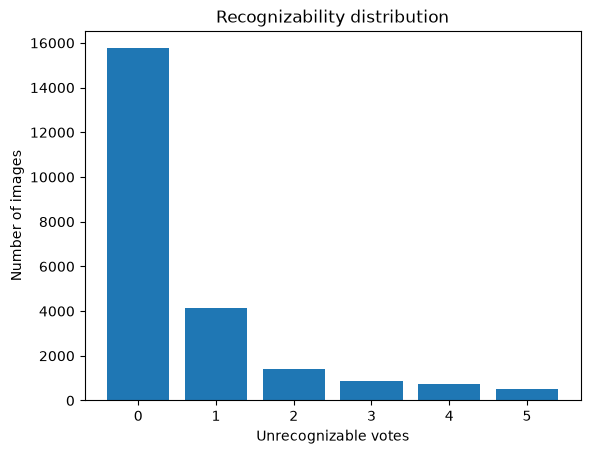

In [36]:
#Printing data distributions for unrecognizability
votes = Counter(
    item["unrecognizable"]
    for item in train_data
)

for count in range(6):
    print(f"{count} votes: {votes[count]} images")

plt.bar(range(6), [votes[i] for i in range(6)])

plt.xlabel("Unrecognizable votes")
plt.ylabel("Number of images")
plt.title("Recognizability distribution")
plt.show()

{'FRM': 1, 'BLR': 5, 'DRK': 0, 'BRT': 3, 'OBS': 0, 'OTH': 0, 'NON': 0, 'ROT': 0}


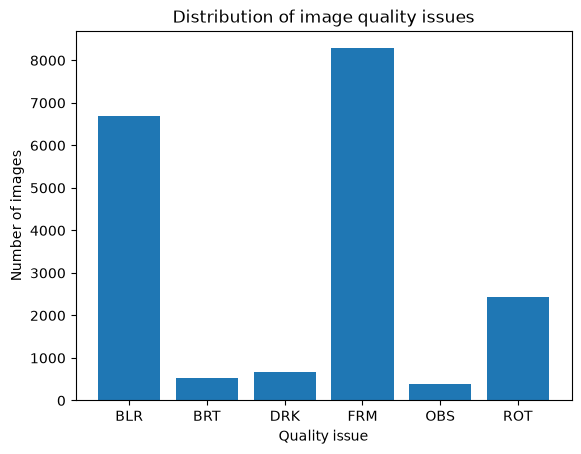

In [37]:
#Printing specific image flaw distribution where values >= 3 means that the flaw is present
print(train_data[0]["flaws"])
flaws = ["BLR", "BRT", "DRK", "FRM", "OBS", "ROT"]

flaw_counts = {
    flaw: sum(item["flaws"][flaw] >= 3 for item in train_data)
    for flaw in flaws
}

plt.bar(flaw_counts.keys(), flaw_counts.values())
plt.xlabel("Quality issue")
plt.ylabel("Number of images")
plt.title("Distribution of image quality issues")
plt.show()

Class for the flaw types

In [38]:
LABELS = ["BLR","BRT","DRK","FRM","OBS","OTH","NON","ROT"]

class VizWizQuality (Dataset):

    def __init__ (self, json_path, img_dir, transform):
        self.items = json.load(open(json_path))
        self.img_dir = Path(img_dir)
        self.transform =  transform

    def __len__ (self): return len(self.items)

    def __getitem__ (self, i):
        it = self.items[i]
        img = Image.open (self.img_dir / it["image"]).convert("RGB")
        x = self.transform(img)

        # checking if there is no data label, then return the filename
        if "flaws" not in it:
            return x, it["image"]

        y = [it["flaws"][k] / 5 for k in LABELS] + [it["unrecognizable"] / 5]
        return x, torch.tensor (y, dtype = torch.float32)


Copying the content from Drive to /content

DO NOT RUN THIS

In [39]:
if IN_COLAB:
    source = Path("/content/drive/MyDrive/vizwiz")
    destination = Path("/content/vizwiz")

    if not source.is_dir():
        raise FileNotFoundError(
            "The vizwiz folder was not found. Add a shortcut to it in My Drive."
        )

    
    print("Copying the dataset... Please wait.")
    shutil.copytree(source, destination, dirs_exist_ok=True)
    print("Done! Files are available at /content/vizwiz")
else:
    print ("Using local data")

NameError: name 'IN_COLAB' is not defined

Transforming the images to 224 x 224

In [ ]:
from torchvision.models import ResNet18_Weights
print(ResNet18_Weights.DEFAULT.transforms())

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [ ]:
model_weights = ResNet18_Weights.DEFAULT

ORIGINAL_MEAN = model_weights.transforms().mean
ORIGINAL_STD = model_weights.transforms().std

train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(ORIGINAL_MEAN,ORIGINAL_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(ORIGINAL_MEAN, ORIGINAL_STD)
])

Creating the dataset for the model to train on

In [ ]:
ANNOTATIONS = DATA / "annotations"
IMG = DATA / "images"

train_dataset = VizWizQuality(ANNOTATIONS / "train.json", IMG / "train", train_transform)
val_dataset = VizWizQuality(ANNOTATIONS / "val.json", IMG / "val", eval_transform)
test_dataset = VizWizQuality(ANNOTATIONS / "test.json", IMG / "test", eval_transform)

print (f"Train dataset size:", len(train_dataset))
print (f"Val dataset size:", len(val_dataset))
print (f"Test dataset size:", len(test_dataset))

x, y = train_dataset[0]
print (x.shape, y)

Train dataset size: 23431
Val dataset size: 7750
Test dataset size: 8000
torch.Size([3, 224, 224]) tensor([1.0000, 0.6000, 0.0000, 0.2000, 0.0000, 0.0000, 0.0000, 0.0000, 0.8000])


Dataloaders

In [ ]:
BATCH_SIZE = 64
loader_args = dict( batch_size = BATCH_SIZE, num_workers = 0, pin_memory = (device.type == "cuda"))

train_loader = DataLoader (train_dataset, shuffle = True, **loader_args)
val_loader = DataLoader (val_dataset, shuffle = False, **loader_args)
test_loader = DataLoader (test_dataset, shuffle = False, **loader_args)

x, y = next(iter(train_loader))
print (x.shape, y.shape)

torch.Size([64, 3, 224, 224]) torch.Size([64, 9])


Loading in ResNet18 and adjuisting the output

In [ ]:
# original model
model = models.resnet18(weights=model_weights)
print(model.fc)

# model adjusted to our purpose
model.fc = nn.Linear(model.fc.in_features, len(LABELS) + 1)
model = model.to(device)
print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\danie/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:02<00:00, 16.1MB/s]


Linear(in_features=512, out_features=1000, bias=True)
Linear(in_features=512, out_features=9, bias=True)


Preliminary evaluation of the model

In [ ]:
criterion = nn.BCEWithLogitsLoss()
run = False

def evaluate (model, loader):
    model.eval()
    total_loss, n = 0.0, 0
    correct = torch.zeros(len(LABELS) + 1)
    always_no = torch.zeros(len(LABELS) + 1)

    with torch.no_grad():
        for x, y in tqdm(loader, desc = "Evaluating"):
            x, y = x.to(device), y.to(device)
            logits = model (x)
            total_loss += criterion(logits, y).item() * x.size(0)  # returns the average loss of this batch

            preds = torch.sigmoid(logits) > 0.5  # threshold for if a flaw exist
            truth = y >= 0.6 # if 3 or more agreed on the flaw
            correct += (preds == truth).sum(dim=0).cpu()
            always_no += (~truth).sum(dim=0).cpu()
            n += x.size(0)

        return total_loss / n, correct / n, always_no / n

if run:
    val_loss, val_acc, baseline_acc = evaluate(model, val_loader)
    print(f"val loss: {val_loss:.4f}")
    for name, a, b in zip(LABELS + ["UNREC"], val_acc, baseline_acc):
        print(f"{name:6} model acc: {a:.3f}   always-'no' acc: {b:.3f}")


Training setup

In [ ]:
NUM_EPOCH = 4
LEARNING_RATE = 1e-4

optimizer = torch.optim.Adam(model.parameters(), lr = LEARNING_RATE)

if IN_COLAB:
    CHECKPOINT_DIR = Path("/content/drive/MyDrive/vizwiz_checkpoints")
    BIS_MODEL_DIR  = Path("/content/drive/MyDrive/vizwiz_bis_model")
else:
    CHECKPOINT_DIR = Path.cwd() / "checkpoints"
    BIS_MODEL_DIR  = Path.cwd() / "bis_model"

CHECKPOINT_DIR.mkdir(exist_ok=True)
BIS_MODEL_DIR.mkdir(exist_ok=True)
BIS_MODEL_PATH = BIS_MODEL_DIR / "resnet18_bis.pt"

NameError: name 'IN_COLAB' is not defined

Traning Function

In [ ]:
def train (model, loader, epoch):
    model.train()
    total_loss, n = 0.0, 0
    bar = tqdm(loader, desc = f"training epoch: {epoch}", leave = False)

    for x, y in bar:
        x, y = x.to(device), y.to(device)  # loads it into the gpu

        logits = model(x)  # predict
        loss = criterion(logits, y)  # checks how off the model was

        optimizer.zero_grad() # clears last batch of gradients 
        loss.backward()  # calculate the graidents to adjust the weights

        optimizer.step() # update weights

        total_loss += loss.item() * x.size(0)
        n+= x.size(0)
        bar.set_postfix(loss = f"{total_loss / n:.4f}")

    return total_loss / n


Training loop

In [ ]:
def training (model, train_loader, val_loader, epochs, save_path):
    history = [] 
    best_val_loss = float("inf")

    for epoch in range(1, epochs + 1):
        train_loss = train(model,train_loader, epoch)
        val_loss, val_acc, _ = evaluate(model, val_loader)

        history.append({
            "epoch" : epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "mean_val_acc": val_acc.mean().item()
        })
        pd.DataFrame(history).to_csv(CHECKPOINT_DIR / "history.csv", index=False)

        print(f"Epoch {epoch}/{epochs} | train loss {train_loss:.4f} " f"| val loss {val_loss:.4f} | mean val acc {val_acc.mean():.3f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), save_path)
            print ("new best model")

    return history

Quick test of training run

In [ ]:
from torch.utils.data import Subset
run = False

if run:
    quick_train = DataLoader(Subset(train_dataset, range(640)), shuffle = True, **loader_args)
    quick_val = DataLoader(Subset(val_dataset, range(320)), shuffle = False, **loader_args)

    history = training(model, quick_train, quick_val, epochs=2, save_path=CHECKPOINT_DIR / "quick_test.pt")

Pre training check

In [ ]:
import inspect

# Is the optimizer updating THIS model's weights?
opt_params = {id(p) for g in optimizer.param_groups for p in g["params"]}
print("optimizer matches model:", all(id(p) in opt_params for p in model.parameters()))

# Is the model the adjusted one, on the GPU?
print("output layer:", model.fc)
print("model on:", next(model.parameters()).device)

# Are the fixed function versions loaded?
print("evaluate uses >= :", ">= 0.6" in inspect.getsource(evaluate))
src = inspect.getsource(training)
print("best_val_loss = inf:", 'float("inf")' in src)
print("unpacks 3 values:", "val_acc, _" in src)
print("stores mean_val_acc:", '"mean_val_acc"' in src)

optimizer matches model: True
output layer: Linear(in_features=512, out_features=9, bias=True)
model on: cuda:0
evaluate uses >= : True
best_val_loss = inf: True
unpacks 3 values: True
stores mean_val_acc: True


Traning the model

In [ ]:
run = True

if run:
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.1, patience=1
    )
    history = training(model, train_loader, val_loader, NUM_EPOCH, BIS_MODEL_PATH)

training epoch: 1:   0%|          | 0/367 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/122 [00:00<?, ?it/s]

Epoch 1/4 | train loss 0.3372 | val loss 0.3011 | mean val acc 0.912
new best model


training epoch: 2:   0%|          | 0/367 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/122 [00:00<?, ?it/s]

Epoch 2/4 | train loss 0.2880 | val loss 0.2990 | mean val acc 0.913
new best model


... (2 outputs left out)

Epoch 3/4 | train loss 0.2777 | val loss 0.2990 | mean val acc 0.914


training epoch: 4:   0%|          | 0/367 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/122 [00:00<?, ?it/s]

Epoch 4/4 | train loss 0.2675 | val loss 0.3026 | mean val acc 0.913


Ploting the learning curve

['epoch', 'train_loss', 'val_loss', 'mean_val_acc']
always-'no' accuracy: 0.8629534244537354


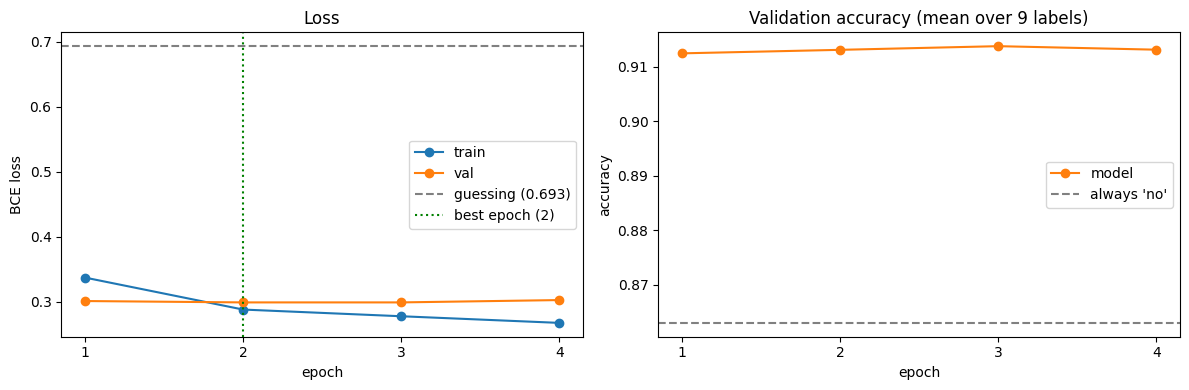

In [ ]:
hist = pd.DataFrame(history).rename(columns={"mean_val_loss": "mean_val_acc"})
print(hist.columns.tolist())
best = hist.loc[hist["val_loss"].idxmin()]     

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(hist["epoch"], hist["train_loss"], marker="o", label="train")
ax1.plot(hist["epoch"], hist["val_loss"],   marker="o", label="val")
ax1.axhline(0.693, linestyle="--", color="gray", label="guessing (0.693)")
ax1.axvline(best["epoch"], linestyle=":", color="green",
            label=f"best epoch ({int(best['epoch'])})")
ax1.set_title("Loss")
ax1.set_xlabel("epoch")
ax1.set_ylabel("BCE loss")
ax1.set_xticks(hist["epoch"])
ax1.legend()

val_truth = torch.tensor([
    [it["flaws"][k] / 5 for k in LABELS] + [it["unrecognizable"] / 5]
    for it in val_dataset.items
]) >= 0.6
baseline_acc = (~val_truth).float().mean(dim=0)
print("always-'no' accuracy:", baseline_acc.mean().item())

ax2.plot(hist["epoch"], hist["mean_val_acc"], marker="o", color="tab:orange", label="model")
ax2.axhline(baseline_acc.mean().item(), linestyle="--", color="gray", label="always 'no'")
ax2.set_title("Validation accuracy (mean over 9 labels)")
ax2.set_xlabel("epoch")
ax2.set_ylabel("accuracy")
ax2.set_xticks(hist["epoch"])
ax2.legend()

plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / "learning_curves.png", dpi=150)
plt.show()

# Displaying detailed results

In [ ]:
def evaluate_detailed(model, loader):
    model.eval()

    labels = LABELS + ["UNREC"]
    tp = torch.zeros(len(labels)) #Each of these four is a true/false positivity/negativity. It seperates results for balanced accuracy
    tn = torch.zeros(len(labels))
    fp = torch.zeros(len(labels))
    fn = torch.zeros(len(labels))

    with torch.no_grad():
        for x, y in tqdm(loader, desc="Evaluating"):
            x = x.to(device)

            logits = model(x)
            preds = (torch.sigmoid(logits) > 0.5).cpu() #Comparing results to actual values
            truth = y >= 0.6

            tp += (preds & truth).sum(dim=0) #Counting each result type
            tn += (~preds & ~truth).sum(dim=0)
            fp += (preds & ~truth).sum(dim=0)
            fn += (~preds & truth).sum(dim=0)

    total = tp + tn + fp + fn

    accuracy = (tp + tn) / total
    baseline = (tn + fp) / total

    precision = tp / (tp + fp).clamp(min=1)
    recall = tp / (tp + fn).clamp(min=1)
    specificity = tn / (tn + fp).clamp(min=1)

    balanced_accuracy = (recall + specificity) / 2
    balanced_accuracy = torch.where(
        ((tp + fn) > 0) & ((tn + fp) > 0),
        balanced_accuracy,
        torch.full_like(balanced_accuracy, float("nan"))
    )

    f1 = 2 * tp / (2 * tp + fp + fn).clamp(min=1)

    return pd.DataFrame({
        "Label": labels,
        "Accuracy": accuracy.numpy(),
        "Baseline": baseline.numpy(),
        "Improvement (pp)": ((accuracy - baseline) * 100).numpy(),
        "Balanced Accuracy": balanced_accuracy.numpy(),
        "Precision": precision.numpy(),
        "Recall": recall.numpy(),
        "F1": f1.numpy()
    })

In [26]:
#Load saved model
from pathlib import Path

MODEL_PATH = Path.cwd() / "bis_model" / "resnet18_bis.pt"

model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)

model.eval()

print("Trained model loaded successfully.")

Trained model loaded successfully.


In [31]:
#Print results
results = evaluate_detailed(model, val_loader)

display_results = results[results["Label"] != "OTH"] #Exclude the "Other" catergory
display(display_results.style.format({
    "Accuracy": "{:.1%}",
    "Baseline": "{:.1%}",
    "Improvement (pp)": "{:+.1f}",
    "Balanced Accuracy": "{:.1%}",
    "Precision": "{:.1%}",
    "Recall": "{:.1%}",
    "F1": "{:.1%}"
}))

Evaluating: 100%|██████████| 122/122 [02:45<00:00,  1.35s/it]


,Label,Accuracy,Baseline,Improvement (pp),Balanced Accuracy,Precision,Recall,F1
0,BLR,84.9%,70.1%,+14.8,79.7%,79.5%,66.7%,72.5%
1,BRT,97.7%,97.4%,+0.3,64.5%,61.5%,29.5%,39.9%
2,DRK,98.3%,97.2%,+1.1,79.6%,75.3%,59.8%,66.7%
3,FRM,74.0%,63.5%,+10.5,70.2%,67.2%,56.2%,61.2%
4,OBS,98.9%,98.5%,+0.3,69.7%,70.8%,39.7%,50.8%
6,NON,81.9%,70.6%,+11.3,77.5%,70.2%,66.7%,68.4%
7,ROT,90.9%,89.1%,+1.8,62.5%,72.8%,26.3%,38.6%
8,UNREC,95.3%,90.3%,+5.0,81.8%,83.3%,65.0%,73.0%


In [33]:
#Save results
RESULTS_DIR = Path.cwd() / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

display_results.to_csv(RESULTS_DIR / "per_label_metrics.csv", index=False)

print("Results saved.")

Results saved.
